# Deepfake Audio Detection for Voice Spoofing Attacks
Author(s): Robert Veloya, Aaron Dang

# Enviroment and Data Set-Up

Imports libraries needed for audio processing, neural-network training, visualization, and evaluation. Allowing reproducablity with seeding. Download and extract ASVspoof 2019 dataset using the Kaggle API.

In [ ]:
import os
import random
import zipfile
import glob

import numpy as np
import librosa
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import userdata

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_curve,
    auc,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    LSTM,
    BatchNormalization
)
from tensorflow.keras.optimizers import Adam

# Reproducibility
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Kaggle credentials
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

# Install Kaggle API
!pip install -q kaggle

# Download dataset
datasets_zip = "/content/asvpoof-2019-dataset.zip"
extract_path = "/content/asvpoof-2019-dataset"

if not os.path.exists(datasets_zip):
    print("Downloading ASVspoof 2019 dataset...")
    !kaggle datasets download -d awsaf49/asvpoof-2019-dataset

if not os.path.exists(extract_path):
    print("Extracting dataset...")
    with zipfile.ZipFile(datasets_zip, "r") as zip_ref:
        zip_ref.extractall(extract_path)

print("ASVspoof 2019 dataset is ready.")

ASVspoof 2019 dataset is ready.


# Audio Preprocessing and Feature Extraction

This cell converts each audio recording into numerical features that can be processed by the neural networks.

The following two feature formats are created
- The CNN receives a 150 × 150 × 3 spectrogram representation
- BiLSTM receives a sequence containing 150 time steps and 128 mel-frequency features.


In [ ]:
# ==========================================
# 1. PREPROCESSING AND FEATURE EXTRACTION
# ==========================================

def extract_audio_histogram_features(
    file_path,
    target_shape=(150, 150)
):
    """
    Converts audio into a normalized 150 x 150 x 3
    log-mel spectrogram representation for the CNN.
    """

    try:
        y, sr = librosa.load(
            file_path,
            sr=16000,
            duration=3.0
        )

        mel_spec = librosa.feature.melspectrogram(
            y=y,
            sr=sr,
            n_mels=target_shape[0]
        )

        mel_spec_db = librosa.power_to_db(
            mel_spec,
            ref=np.max
        )

        # Pad or truncate the time dimension
        if mel_spec_db.shape[1] < target_shape[1]:
            pad_width = target_shape[1] - mel_spec_db.shape[1]

            mel_spec_db = np.pad(
                mel_spec_db,
                ((0, 0), (0, pad_width)),
                mode="constant"
            )
        else:
            mel_spec_db = mel_spec_db[:, :target_shape[1]]

        # Convert to three identical channels for CNN input
        feature_image = np.stack(
            [mel_spec_db, mel_spec_db, mel_spec_db],
            axis=-1
        )

        # Normalize to [0, 1]
        feature_image = (
            feature_image - feature_image.min()
        ) / (
            feature_image.max() - feature_image.min() + 1e-8
        )

        return feature_image

    except Exception as e:
        print(f"Error processing {file_path} for CNN: {e}")
        return None


def extract_lstm_sequence_features(
    file_path,
    max_pad_len=150
):
    """
    Converts audio into a normalized sequence shaped:
    (150 time steps, 128 mel-frequency features)
    for the LSTM.
    """

    try:
        y, sr = librosa.load(
            file_path,
            sr=16000,
            duration=3.0
        )

        mel_spec = librosa.feature.melspectrogram(
            y=y,
            sr=sr,
            n_mels=128
        )

        mel_spec_db = librosa.power_to_db(
            mel_spec,
            ref=np.max
        )

        # Shape becomes (time steps, frequency features)
        mel_spec_db = mel_spec_db.T

        # Pad or truncate the time dimension
        if mel_spec_db.shape[0] < max_pad_len:
            pad_width = max_pad_len - mel_spec_db.shape[0]

            mel_spec_db = np.pad(
                mel_spec_db,
                ((0, pad_width), (0, 0)),
                mode="constant"
            )
        else:
            mel_spec_db = mel_spec_db[:max_pad_len, :]

        # Normalize to [0, 1]
        mel_spec_db = (
            mel_spec_db - mel_spec_db.min()
        ) / (
            mel_spec_db.max() - mel_spec_db.min() + 1e-8
        )

        return mel_spec_db

    except Exception as e:
        print(f"Error processing {file_path} for LSTM: {e}")
        return None

# Baseline Model Architectures

This cell defines the two baseline detection models. The CNN analyzes spectrograms as two-dimensional images and learns local time-frequency patterns. The BiLSTM analyzes the spectrogram as a sequence and learns temporal patterns in the audio.

Both models produce a sigmoid score representing how likely the recording is to be bonafide.

In [ ]:
# ==========================================
# 2. BASELINE MODEL ARCHITECTURE (Deep4SNet Style)
# ==========================================
def build_baseline_detector(input_shape=(150, 150, 3)):
    """
    Constructs a baseline CNN classifier taking 2D structural audio representations
    as input and outputting a binary classification score (Real vs Fake)[cite: 2].
    """
    model = Sequential([
        Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=input_shape),
        MaxPooling2D(pool_size=(2, 2)),

        Conv2D(32, kernel_size=(3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),

        Conv2D(32, kernel_size=(3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),

        Flatten(),
        Dense(64, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid') # Binary: 0 for Fake, 1 for Real[cite: 3]
    ])

    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

# LSTM
def build_lstm_detector(input_shape=(150, 128)):
  """
  Constructs a multi-layered Bi-directional LSTM baseline
  to capture temporal context in speech synthesis artifacts.
  """
  model = Sequential([
      tf.keras.layers.Bidirectional(LSTM(64, return_sequences=True), input_shape=input_shape),
      Dropout(0.3),
      BatchNormalization(),

      tf.keras.layers.Bidirectional(LSTM(32, return_sequences=False)),
      Dropout(0.3),
      BatchNormalization(),

      Dense(32, activation='relu'),
      Dropout(0.5),

      Dense(1, activation='sigmoid')
  ])

  model.compile(optimizer=Adam(learning_rate=1e-4),
                loss='binary_crossentropy',
                metrics=['accuracy'])
  return model


# Evaluation Metrics and Training Visualizations

This cell defines the evaluation and visualization functions used throughout the experiment. The Equal Error Rate measures the point where the false acceptance rate and false rejection rate are approximately equal.

The plotting functions display training loss, accuracy, ROC curves, AUC, and EER for the baseline models.

In [ ]:
# ==========================================
# 3. EVALUATION METRIC: EQUAL ERROR RATE (EER)
# ==========================================
def calculate_eer(y_true, y_scores):
    """
    Calculates the Equal Error Rate (EER) where False Acceptance Rate (FAR)
    equals False Rejection Rate (FRR) to evaluate model generalizability[cite: 3].
    """
    fpr, tpr, thresholds = roc_curve(y_true, y_scores, pos_label=1)
    fnr = 1 - tpr
    # Find the threshold where absolute difference between fpr and fnr is minimal
    eer_threshold_idx = np.nanargmin(np.absolute(fpr - fnr))
    eer = (fpr[eer_threshold_idx] + fnr[eer_threshold_idx]) / 2
    return eer, thresholds[eer_threshold_idx]

def plot_training_history(history, model_name="CNN"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(history.history['loss'], label='Train Loss')
    if 'val_loss' in history.history:
        ax1.plot(history.history['val_loss'], label='Val Loss')
    ax1.set_title(f'{model_name} - Model Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()

    ax2.plot(history.history['accuracy'], label='Train Accuracy')
    if 'val_accuracy' in history.history:
        ax2.plot(history.history['val_accuracy'], label='Val Accuracy')
    ax2.set_title(f'{model_name} - Model Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.legend()

    plt.tight_layout()
    plt.show()

def plot_comparative_roc_and_eer(y_val, cnn_scores, lstm_scores):
    """
    Plots a direct comparative ROC curve for both CNN and LSTM baselines,
    displaying their respective EER operating points on the same graph for slides/reports.
    """
    plt.figure(figsize=(7, 7))

    # 1. CNN ROC Curve
    fpr_cnn, tpr_cnn, _ = roc_curve(y_val, cnn_scores, pos_label=1)
    fnr_cnn = 1 - tpr_cnn
    idx_cnn = np.nanargmin(np.absolute(fpr_cnn - fnr_cnn))
    eer_cnn = (fpr_cnn[idx_cnn] + fnr_cnn[idx_cnn]) / 2
    auc_cnn = auc(fpr_cnn, tpr_cnn)
    plt.plot(fpr_cnn, tpr_cnn, color='blue', lw=2, label=f'CNN Baseline (AUC = {auc_cnn:.3f}, EER = {eer_cnn:.3f})')
    plt.scatter(fpr_cnn[idx_cnn], tpr_cnn[idx_cnn], color='blue', s=60, zorder=5)

    # 2. LSTM ROC Curve
    fpr_lstm, tpr_lstm, _ = roc_curve(y_val, lstm_scores, pos_label=1)
    fnr_lstm = 1 - tpr_lstm
    idx_lstm = np.nanargmin(np.absolute(fpr_lstm - fnr_lstm))
    eer_lstm = (fpr_lstm[idx_lstm] + fnr_lstm[idx_lstm]) / 2
    auc_lstm = auc(fpr_lstm, tpr_lstm)
    plt.plot(fpr_lstm, tpr_lstm, color='green', lw=2, label=f'LSTM Baseline (AUC = {auc_lstm:.3f}, EER = {eer_lstm:.3f})')
    plt.scatter(fpr_lstm[idx_lstm], tpr_lstm[idx_lstm], color='green', s=60, zorder=5)

    # Diagonal reference line
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')

    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (FAR)')
    plt.ylabel('True Positive Rate (1 - FRR)')
    plt.title('Comparative ROC Curves: CNN vs. LSTM Baselines')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

# Model Initialization Check

This cell creates both baseline models and displays their architectures. It confirms that the CNN and BiLSTM can be successfully initialized before they are connected to the dataset and trained.

In [ ]:
# ==========================================
# 4. EXECUTION PIPELINE EXAMPLE
# ==========================================
if __name__ == "__main__":
    print("Initializing baseline components...")

    # Instantiate baseline model
    model = build_baseline_detector()
    model.summary()

    print("\nBaseline architecture built successfully. Ready to bind with ASVspoof 2019 dataset directories[cite: 3].")

    lstm_model = build_lstm_detector()
    lstm_model.summary()

    print("\nLSTM architecture built successfully. Ready to bind with ASVspoof 2019 dataset directories[cite: 3].")

Initializing baseline components...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9248)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       591,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 611,393 (2.33 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 150, 128)       │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 150, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 142,913 (558.25 KB)

 Trainable params: 142,529 (556.75 KB)

 Non-trainable params: 384 (1.50 KB)


LSTM architecture built successfully. Ready to bind with ASVspoof 2019 dataset directories[cite: 3].


# Dataset Loading, Exploratory Analysis, and Model Training

This cell reads the ASVspoof protocol file and assigns binary labels to the audio recordings. It then extracts CNN and BiLSTM features from the audio files.

The cell also performs exploratory data analysis by visualizing the class distribution, example spectrograms, and spectrogram energy statistics. Finally, the data is divided into reproducible stratified training and validation sets before both baseline models are trained.

Processing 1000 audio files...
CNN data shape: (1000, 150, 150, 3)
LSTM data shape: (1000, 150, 128)
Labels shape: (1000,)


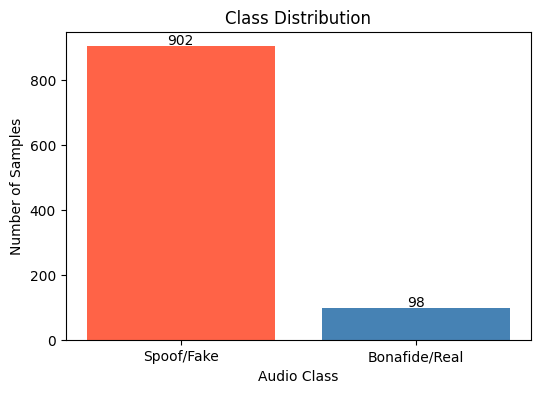

Class counts:
Spoof/Fake: 902
Bonafide/Real: 98
Total samples: 1000


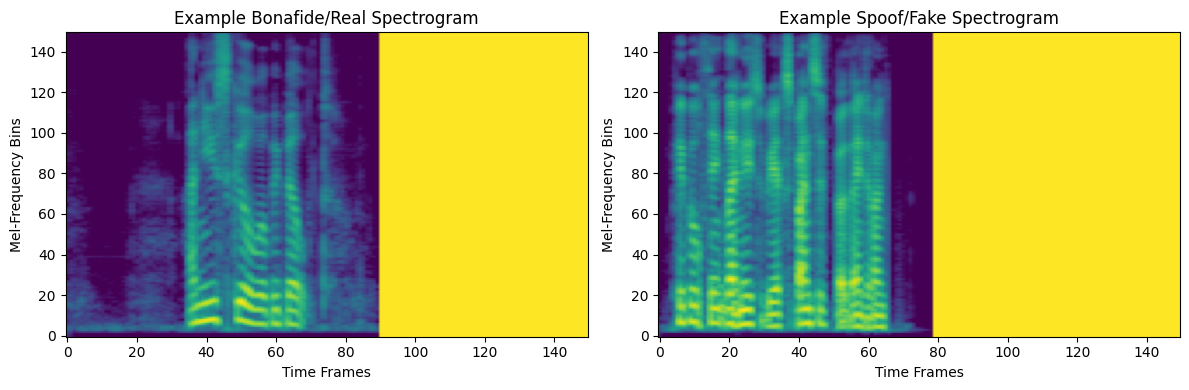

/tmp/ipykernel_845/21888420.py:155: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


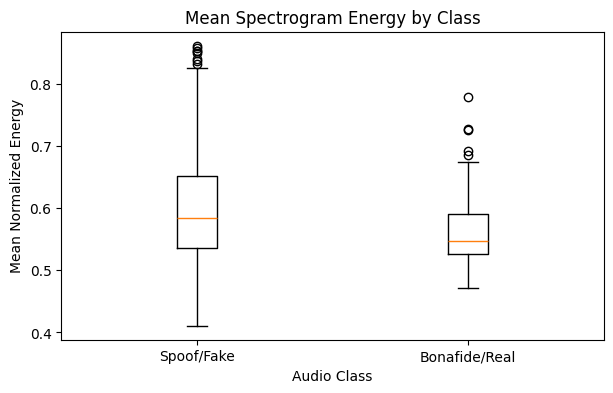

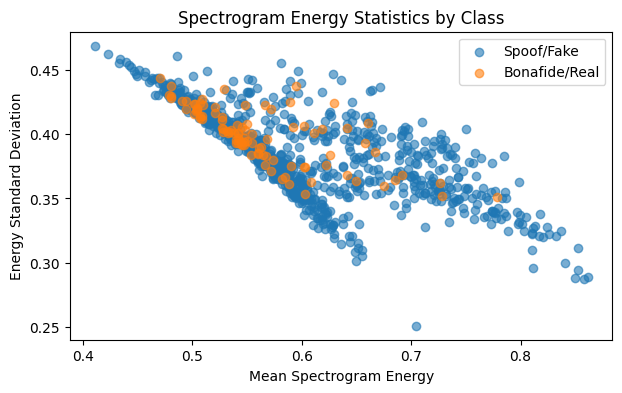

Training samples: 800
Validation samples: 200

Training CNN baseline...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 26s 925ms/step - accuracy: 0.9000 - loss: 0.3557 - val_accuracy: 0.9000 - val_loss: 0.3253
Epoch 2/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 41s 974ms/step - accuracy: 0.9025 - loss: 0.3198 - val_accuracy: 0.9000 - val_loss: 0.3185
Epoch 3/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 38s 855ms/step - accuracy: 0.9025 - loss: 0.3131 - val_accuracy: 0.9000 - val_loss: 0.3151
Epoch 4/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 22s 869ms/step - accuracy: 0.9025 - loss: 0.3051 - val_accuracy: 0.9000 - val_loss: 0.3114
Epoch 5/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 41s 886ms/step - accuracy: 0.9025 - loss: 0.2973 - val_accuracy: 0.9000 - val_loss: 0.3082


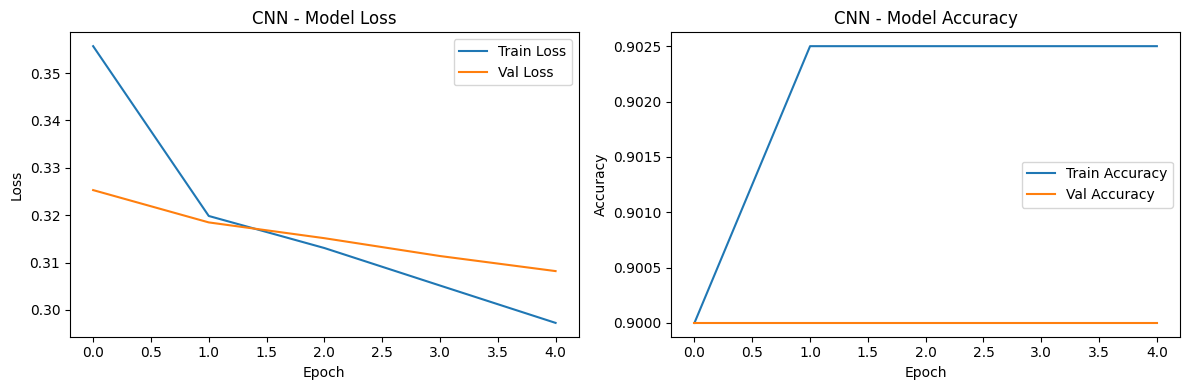

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 185ms/step

Training BiLSTM baseline...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 13s 258ms/step - accuracy: 0.6075 - loss: 0.7445 - val_accuracy: 0.9000 - val_loss: 0.6210
Epoch 2/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 268ms/step - accuracy: 0.6438 - loss: 0.6923 - val_accuracy: 0.9000 - val_loss: 0.6083
Epoch 3/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 218ms/step - accuracy: 0.6750 - loss: 0.6353 - val_accuracy: 0.9000 - val_loss: 0.5781
Epoch 4/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 10s 227ms/step - accuracy: 0.6637 - loss: 0.6331 - val_accuracy: 0.9000 - val_loss: 0.5416
Epoch 5/5
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 280ms/step - accuracy: 0.7125 - loss: 0.5816 - val_accuracy: 0.9000 - val_loss: 0.5062


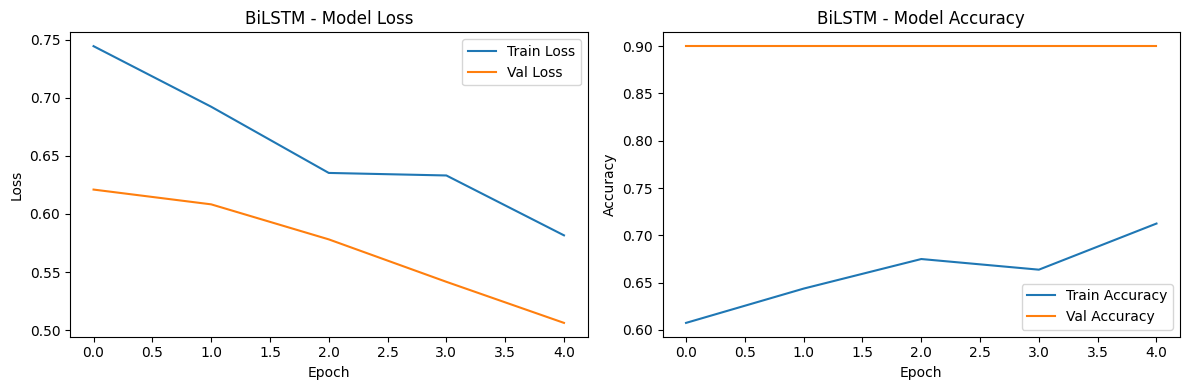

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 151ms/step

Training and prediction complete.


In [ ]:
# ==========================================
# DATA LOADING, EDA, SPLITTING, AND TRAINING
# ==========================================

AUDIO_DIR = (
    "/content/asvpoof-2019-dataset/"
    "LA/LA/ASVspoof2019_LA_train/flac/"
)

PROTOCOL_FILE = (
    "/content/asvpoof-2019-dataset/"
    "LA/LA/ASVspoof2019_LA_cm_protocols/"
    "ASVspoof2019.LA.cm.train.trn.txt"
)

# ------------------------------------------
# Read labels from the protocol file
# ------------------------------------------

labels_dict = {}

with open(PROTOCOL_FILE, "r") as f:
    for line in f:
        parts = line.strip().split()

        if len(parts) >= 5:
            file_id = parts[1]
            label = parts[4]

            # 1 = bonafide/real
            # 0 = spoof/fake
            labels_dict[file_id] = (
                1 if label == "bonafide" else 0
            )

# ------------------------------------------
# Select audio files
# ------------------------------------------

all_files = sorted(
    glob.glob(os.path.join(AUDIO_DIR, "*.flac"))
)

selected_files = all_files[:1000]

X_cnn = []
X_lstm = []
y = []
valid_files = []

print(f"Processing {len(selected_files)} audio files...")

for file_path in selected_files:
    file_id = os.path.splitext(
        os.path.basename(file_path)
    )[0]

    if file_id not in labels_dict:
        continue

    cnn_feature = extract_audio_histogram_features(
        file_path
    )

    lstm_feature = extract_lstm_sequence_features(
        file_path
    )

    if cnn_feature is not None and lstm_feature is not None:
        X_cnn.append(cnn_feature)
        X_lstm.append(lstm_feature)
        y.append(labels_dict[file_id])
        valid_files.append(file_path)

X_cnn = np.array(X_cnn)
X_lstm = np.array(X_lstm)
y = np.array(y)

print(f"CNN data shape: {X_cnn.shape}")
print(f"LSTM data shape: {X_lstm.shape}")
print(f"Labels shape: {y.shape}")

# ------------------------------------------
# Class distribution
# ------------------------------------------

class_counts = np.bincount(y)

plt.figure(figsize=(6, 4))

bars = plt.bar(
    ["Spoof/Fake", "Bonafide/Real"],
    class_counts,
    color=["tomato", "steelblue"]
)

plt.title("Class Distribution")
plt.xlabel("Audio Class")
plt.ylabel("Number of Samples")

for bar, count in zip(bars, class_counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        count + 5,
        str(count),
        ha="center"
    )

plt.show()

print("Class counts:")
print(f"Spoof/Fake: {class_counts[0]}")
print(f"Bonafide/Real: {class_counts[1]}")
print(f"Total samples: {len(y)}")

# ------------------------------------------
# Example spectrograms
# ------------------------------------------

real_index = np.where(y == 1)[0][0]
fake_index = np.where(y == 0)[0][0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(
    X_cnn[real_index, :, :, 0],
    aspect="auto",
    origin="lower"
)
axes[0].set_title("Example Bonafide/Real Spectrogram")
axes[0].set_xlabel("Time Frames")
axes[0].set_ylabel("Mel-Frequency Bins")

axes[1].imshow(
    X_cnn[fake_index, :, :, 0],
    aspect="auto",
    origin="lower"
)
axes[1].set_title("Example Spoof/Fake Spectrogram")
axes[1].set_xlabel("Time Frames")
axes[1].set_ylabel("Mel-Frequency Bins")

plt.tight_layout()
plt.show()

# ------------------------------------------
# Feature-statistics analysis
# ------------------------------------------

mean_energy = X_cnn[:, :, :, 0].mean(axis=(1, 2))
std_energy = X_cnn[:, :, :, 0].std(axis=(1, 2))

plt.figure(figsize=(7, 4))

plt.boxplot(
    [
        mean_energy[y == 0],
        mean_energy[y == 1]
    ],
    labels=["Spoof/Fake", "Bonafide/Real"]
)

plt.title("Mean Spectrogram Energy by Class")
plt.xlabel("Audio Class")
plt.ylabel("Mean Normalized Energy")
plt.show()

plt.figure(figsize=(7, 4))

plt.scatter(
    mean_energy[y == 0],
    std_energy[y == 0],
    alpha=0.6,
    label="Spoof/Fake"
)

plt.scatter(
    mean_energy[y == 1],
    std_energy[y == 1],
    alpha=0.6,
    label="Bonafide/Real"
)

plt.title("Spectrogram Energy Statistics by Class")
plt.xlabel("Mean Spectrogram Energy")
plt.ylabel("Energy Standard Deviation")
plt.legend()
plt.show()

# ------------------------------------------
# Reproducible stratified split
# ------------------------------------------

indices = np.arange(len(y))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

X_cnn_train = X_cnn[train_indices]
X_cnn_val = X_cnn[val_indices]

X_lstm_train = X_lstm[train_indices]
X_lstm_val = X_lstm[val_indices]

y_train = y[train_indices]
y_val = y[val_indices]

print(f"Training samples: {len(y_train)}")
print(f"Validation samples: {len(y_val)}")

# ------------------------------------------
# Train CNN baseline
# ------------------------------------------

print("\nTraining CNN baseline...")

cnn_model = build_baseline_detector()

cnn_history = cnn_model.fit(
    X_cnn_train,
    y_train,
    validation_data=(X_cnn_val, y_val),
    epochs=5,
    batch_size=32,
    shuffle=True
)

plot_training_history(
    cnn_history,
    model_name="CNN"
)

cnn_scores = cnn_model.predict(
    X_cnn_val
).ravel()

# ------------------------------------------
# Train BiLSTM baseline
# ------------------------------------------

print("\nTraining BiLSTM baseline...")

lstm_model = build_lstm_detector()

lstm_history = lstm_model.fit(
    X_lstm_train,
    y_train,
    validation_data=(X_lstm_val, y_val),
    epochs=5,
    batch_size=32,
    shuffle=True
)

plot_training_history(
    lstm_history,
    model_name="BiLSTM"
)

lstm_scores = lstm_model.predict(
    X_lstm_val
).ravel()

print("\nTraining and prediction complete.")

# Model Evaluation and Error Analysis

This cell evaluates the trained CNN and BiLSTM models using accuracy, balanced accuracy, precision, recall, F1-score, confusion matrices, ROC-AUC, and Equal Error Rate.

It also identifies misclassified validation examples. This analysis helps determine whether the models are making errors primarily on spoofed or bonafide recordings and shows how class imbalance affects the results.


========== CNN RESULTS ==========
Accuracy: 0.9000
Balanced Accuracy: 0.5000
ROC-AUC: 0.6272
EER: 0.4028
EER Threshold: 0.1097

Confusion Matrix Counts:
True Negatives: 180
False Positives: 0
False Negatives: 20
True Positives: 0

Classification Report:
               precision    recall  f1-score   support

   Spoof/Fake       0.90      1.00      0.95       180
Bonafide/Real       0.00      0.00      0.00        20

     accuracy                           0.90       200
    macro avg       0.45      0.50      0.47       200
 weighted avg       0.81      0.90      0.85       200



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


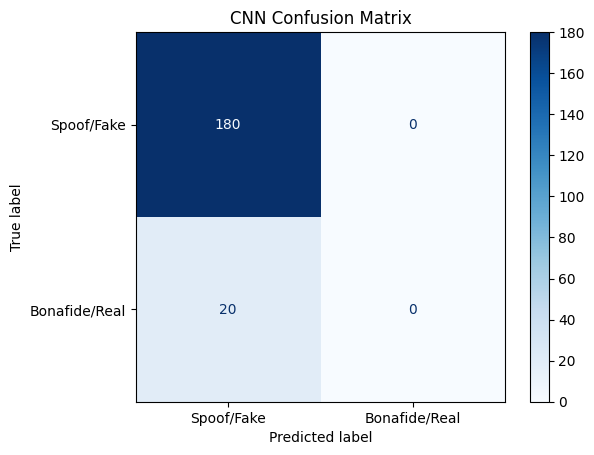

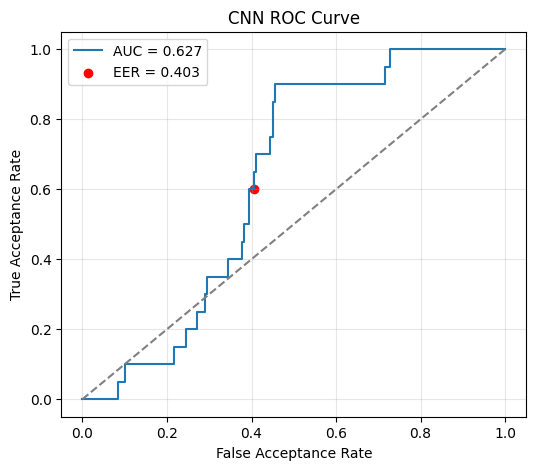


========== BiLSTM RESULTS ==========
Accuracy: 0.9000
Balanced Accuracy: 0.5000
ROC-AUC: 0.8325
EER: 0.2028
EER Threshold: 0.3895

Confusion Matrix Counts:
True Negatives: 180
False Positives: 0
False Negatives: 20
True Positives: 0

Classification Report:
               precision    recall  f1-score   support

   Spoof/Fake       0.90      1.00      0.95       180
Bonafide/Real       0.00      0.00      0.00        20

     accuracy                           0.90       200
    macro avg       0.45      0.50      0.47       200
 weighted avg       0.81      0.90      0.85       200



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


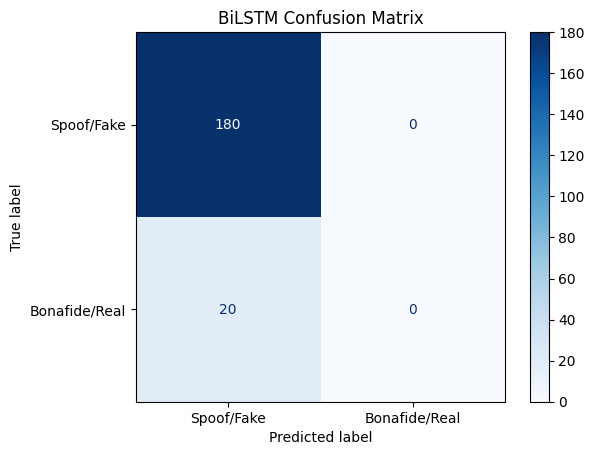

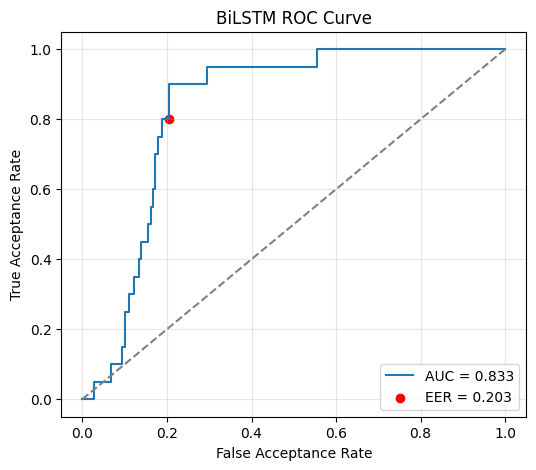


CNN misclassified 20 out of 200 validation samples.

First 10 CNN misclassified examples:
File: /content/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1021790.flac
Actual label: Bonafide/Real
Predicted label: Spoof/Fake
Prediction score: 0.1125
--------------------------------------------------
File: /content/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1312618.flac
Actual label: Bonafide/Real
Predicted label: Spoof/Fake
Prediction score: 0.0919
--------------------------------------------------
File: /content/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1215743.flac
Actual label: Bonafide/Real
Predicted label: Spoof/Fake
Prediction score: 0.0971
--------------------------------------------------
File: /content/asvpoof-2019-dataset/LA/LA/ASVspoof2019_LA_train/flac/LA_T_1186717.flac
Actual label: Bonafide/Real
Predicted label: Spoof/Fake
Prediction score: 0.1252
--------------------------------------------------
File: /content/asvpoof-2019-datas

In [ ]:
# ==========================================
# 5. COMPLETE EVALUATION
# ==========================================

def evaluate_model(model_name, y_true, scores):
    """
    Reports accuracy, balanced accuracy, AUC, EER,
    classification metrics, and the confusion matrix.
    """

    # Use 0.5 as the classification threshold
    predictions = (scores >= 0.5).astype(int)

    # ROC and EER
    fpr, tpr, thresholds = roc_curve(
        y_true,
        scores,
        pos_label=1
    )

    fnr = 1 - tpr

    eer_index = np.nanargmin(
        np.abs(fpr - fnr)
    )

    eer = (
        fpr[eer_index] + fnr[eer_index]
    ) / 2

    eer_threshold = thresholds[eer_index]
    model_auc = auc(fpr, tpr)

    # Confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    accuracy = (tp + tn) / (
        tp + tn + fp + fn
    )

    balanced_accuracy = balanced_accuracy_score(
        y_true,
        predictions
    )

    print(f"\n========== {model_name} RESULTS ==========")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Balanced Accuracy: {balanced_accuracy:.4f}")
    print(f"ROC-AUC: {model_auc:.4f}")
    print(f"EER: {eer:.4f}")
    print(f"EER Threshold: {eer_threshold:.4f}")

    print("\nConfusion Matrix Counts:")
    print(f"True Negatives: {tn}")
    print(f"False Positives: {fp}")
    print(f"False Negatives: {fn}")
    print(f"True Positives: {tp}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            predictions,
            target_names=[
                "Spoof/Fake",
                "Bonafide/Real"
            ]
        )
    )

    # Confusion matrix plot
    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    )

    display_plot = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Spoof/Fake",
            "Bonafide/Real"
        ]
    )

    display_plot.plot(cmap="Blues")
    plt.title(f"{model_name} Confusion Matrix")
    plt.show()

    # ROC curve
    plt.figure(figsize=(6, 5))
    plt.plot(
        fpr,
        tpr,
        label=f"AUC = {model_auc:.3f}"
    )
    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray"
    )
    plt.scatter(
        fpr[eer_index],
        tpr[eer_index],
        color="red",
        label=f"EER = {eer:.3f}"
    )
    plt.title(f"{model_name} ROC Curve")
    plt.xlabel("False Acceptance Rate")
    plt.ylabel("True Acceptance Rate")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    return {
        "predictions": predictions,
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "auc": model_auc,
        "eer": eer,
        "eer_threshold": eer_threshold
    }


cnn_results = evaluate_model(
    "CNN",
    y_val,
    cnn_scores
)

lstm_results = evaluate_model(
    "BiLSTM",
    y_val,
    lstm_scores
)

# ------------------------------------------
# CNN error analysis
# ------------------------------------------

cnn_predictions = cnn_results["predictions"]

misclassified_indices = np.where(
    cnn_predictions != y_val
)[0]

print(
    f"\nCNN misclassified "
    f"{len(misclassified_indices)} "
    f"out of {len(y_val)} validation samples."
)

print("\nFirst 10 CNN misclassified examples:")

for validation_position in misclassified_indices[:10]:

    original_index = val_indices[
        validation_position
    ]

    actual_label = (
        "Bonafide/Real"
        if y_val[validation_position] == 1
        else "Spoof/Fake"
    )

    predicted_label = (
        "Bonafide/Real"
        if cnn_predictions[validation_position] == 1
        else "Spoof/Fake"
    )

    print(f"File: {valid_files[original_index]}")
    print(f"Actual label: {actual_label}")
    print(f"Predicted label: {predicted_label}")
    print(
        f"Prediction score: "
        f"{cnn_scores[validation_position]:.4f}"
    )
    print("-" * 50)